<a href="https://colab.research.google.com/github/raghaveni-p/aas/blob/main/Copy_of_ml_casestudy.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
pip install pandas numpy matplotlib seaborn scikit-learn ucimlrepo

In [ ]:
# Step 1: Import required libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split

from sklearn.tree import DecisionTreeClassifier
from sklearn.tree import plot_tree
from sklearn.tree import export_text
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier

from sklearn.metrics import accuracy_score, classification_report

In [ ]:
pip install pandas numpy matplotlib scikit-learn

In [ ]:
# Step 2: Load the dataset

columns = [
    'class', 'cap-shape', 'cap-surface', 'cap-color',
    'bruises', 'odor', 'gill-attachment', 'gill-spacing',
    'gill-size', 'gill-color', 'stalk-shape', 'stalk-root',
    'stalk-surface-above-ring', 'stalk-surface-below-ring',
    'stalk-color-above-ring', 'stalk-color-below-ring',
    'veil-type', 'veil-color', 'ring-number', 'ring-type',
    'spore-print-color', 'population', 'habitat'
]

url = "https://archive.ics.uci.edu/ml/machine-learning-databases/mushroom/agaricus-lepiota.data"

df = pd.read_csv(url, names=columns)

# Display first five rows
print(df.head())

# Display dataset shape
print("Dataset Shape:", df.shape)

# Display dataset information
print(df.info())

# Check class distribution
print(df['class'].value_counts())

  class cap-shape cap-surface cap-color bruises odor gill-attachment  \
0     p         x           s         n       t    p               f   
1     e         x           s         y       t    a               f   
2     e         b           s         w       t    l               f   
3     p         x           y         w       t    p               f   
4     e         x           s         g       f    n               f   

  gill-spacing gill-size gill-color  ... stalk-surface-below-ring  \
0            c         n          k  ...                        s   
1            c         b          k  ...                        s   
2            c         b          n  ...                        s   
3            c         n          n  ...                        s   
4            w         b          k  ...                        s   

  stalk-color-above-ring stalk-color-below-ring veil-type veil-color  \
0                      w                      w         p          w   
1       

In [ ]:
# Step 3: Data preprocessing

# Separate features and target
X = df.drop('class', axis=1)
y = df['class']

# Convert categorical data into numerical data
X = pd.get_dummies(X, dtype=int)

# Display processed data
print(X.head())

# Display target values
print(y.head())

# Check new dataset shape
print("Processed Dataset Shape:", X.shape)

   cap-shape_b  cap-shape_c  cap-shape_f  cap-shape_k  cap-shape_s  \
0            0            0            0            0            0   
1            0            0            0            0            0   
2            1            0            0            0            0   
3            0            0            0            0            0   
4            0            0            0            0            0   

   cap-shape_x  cap-surface_f  cap-surface_g  cap-surface_s  cap-surface_y  \
0            1              0              0              1              0   
1            1              0              0              1              0   
2            0              0              0              1              0   
3            1              0              0              0              1   
4            1              0              0              1              0   

   ...  population_s  population_v  population_y  habitat_d  habitat_g  \
0  ...             1             0  

In [ ]:
# Step 4: Split data into training and testing sets

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Display dataset sizes
print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (6499, 117)
Testing data: (1625, 117)


In [ ]:
# Step 5: Decision Tree Classifier

# Create model
dt_model = DecisionTreeClassifier(random_state=42)

# Train model
dt_model.fit(X_train, y_train)

# Make predictions
y_pred_dt = dt_model.predict(X_test)

# Calculate accuracy
accuracy_dt = accuracy_score(y_test, y_pred_dt)

print("Decision Tree Accuracy:", accuracy_dt * 100)

# Classification report
print(classification_report(y_test, y_pred_dt))

Decision Tree Accuracy: 100.0
              precision    recall  f1-score   support

           e       1.00      1.00      1.00       843
           p       1.00      1.00      1.00       782

    accuracy                           1.00      1625
   macro avg       1.00      1.00      1.00      1625
weighted avg       1.00      1.00      1.00      1625



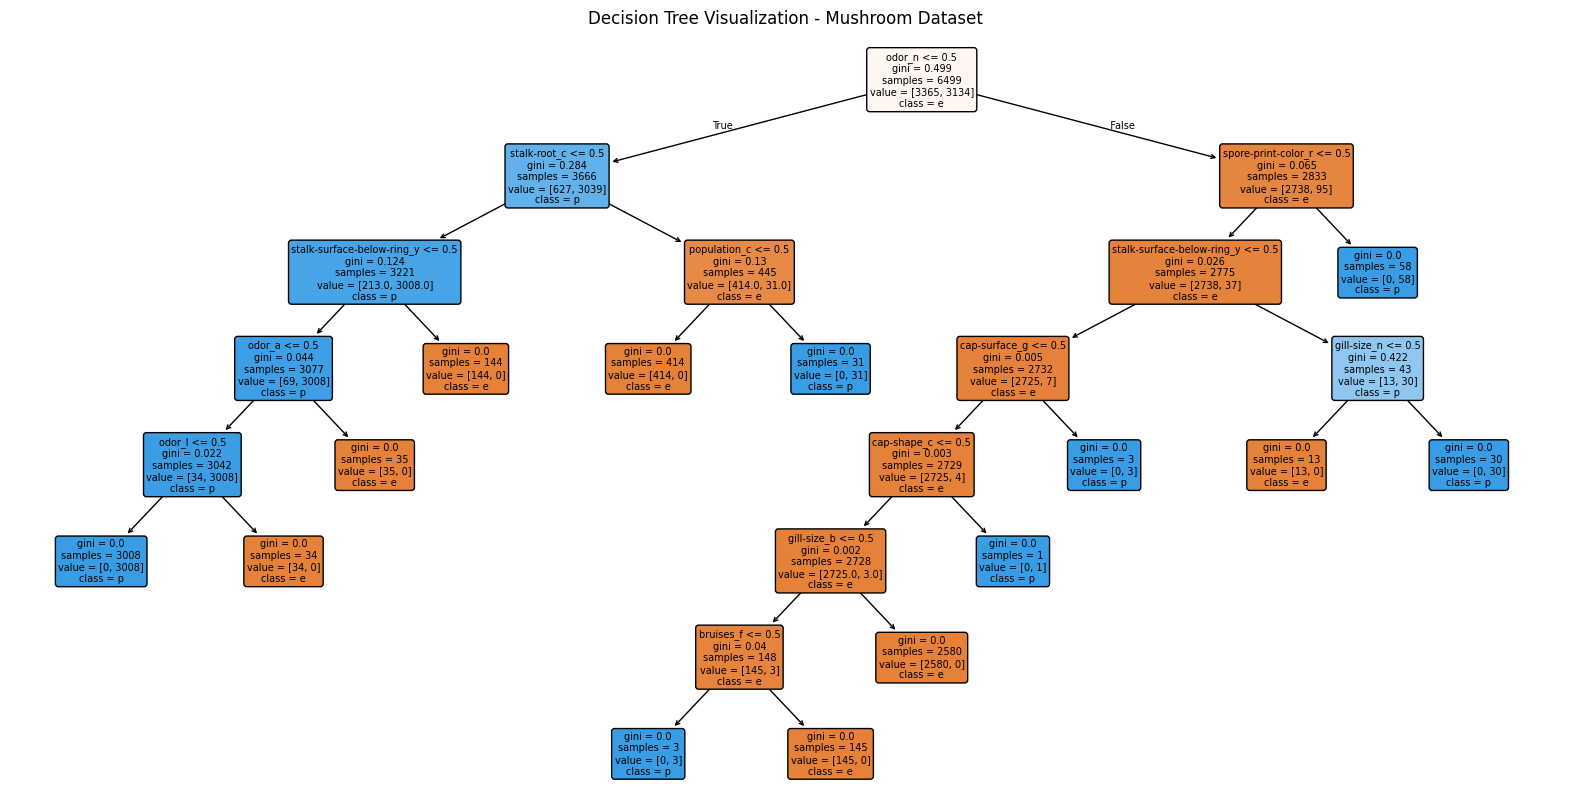

In [ ]:
# Step 8: Visualize the Decision Tree

plt.figure(figsize=(20, 10))

plot_tree(
    dt_model,
    feature_names=X.columns,
    class_names=['e', 'p'],
    filled=True,
    rounded=True,
    fontsize=7
)

plt.title("Decision Tree Visualization - Mushroom Dataset")
plt.show()

In [ ]:
# Step 9: Display Decision Rules

print("\nDecision Rules:\n")

rules = export_text(
    dt_model,
    feature_names=list(X.columns)
)

print(rules)


Decision Rules:

|--- odor_n <= 0.50
|   |--- stalk-root_c <= 0.50
|   |   |--- stalk-surface-below-ring_y <= 0.50
|   |   |   |--- odor_a <= 0.50
|   |   |   |   |--- odor_l <= 0.50
|   |   |   |   |   |--- class: p
|   |   |   |   |--- odor_l >  0.50
|   |   |   |   |   |--- class: e
|   |   |   |--- odor_a >  0.50
|   |   |   |   |--- class: e
|   |   |--- stalk-surface-below-ring_y >  0.50
|   |   |   |--- class: e
|   |--- stalk-root_c >  0.50
|   |   |--- population_c <= 0.50
|   |   |   |--- class: e
|   |   |--- population_c >  0.50
|   |   |   |--- class: p
|--- odor_n >  0.50
|   |--- spore-print-color_r <= 0.50
|   |   |--- stalk-surface-below-ring_y <= 0.50
|   |   |   |--- cap-surface_g <= 0.50
|   |   |   |   |--- cap-shape_c <= 0.50
|   |   |   |   |   |--- gill-size_b <= 0.50
|   |   |   |   |   |   |--- bruises_f <= 0.50
|   |   |   |   |   |   |   |--- class: p
|   |   |   |   |   |   |--- bruises_f >  0.50
|   |   |   |   |   |   |   |--- class: e
|   |   |   |   | 

In [ ]:
# Step 6: Naive Bayes Classifier

# Create model
nb_model = GaussianNB()

# Train model
nb_model.fit(X_train, y_train)

# Make predictions
y_pred_nb = nb_model.predict(X_test)

# Calculate accuracy
accuracy_nb = accuracy_score(y_test, y_pred_nb)

print("Naive Bayes Accuracy:", accuracy_nb * 100)

# Classification report
print(classification_report(y_test, y_pred_nb))

Naive Bayes Accuracy: 96.0
              precision    recall  f1-score   support

           e       1.00      0.92      0.96       843
           p       0.92      1.00      0.96       782

    accuracy                           0.96      1625
   macro avg       0.96      0.96      0.96      1625
weighted avg       0.96      0.96      0.96      1625



In [ ]:
# Step 7: KNN Classifier

# Create model
knn_model = KNeighborsClassifier(n_neighbors=5)

# Train model
knn_model.fit(X_train, y_train)

# Make predictions
y_pred_knn = knn_model.predict(X_test)

# Calculate accuracy
accuracy_knn = accuracy_score(y_test, y_pred_knn)

print("KNN Accuracy:", accuracy_knn * 100)

# Classification report
print(classification_report(y_test, y_pred_knn))

KNN Accuracy: 100.0
              precision    recall  f1-score   support

           e       1.00      1.00      1.00       843
           p       1.00      1.00      1.00       782

    accuracy                           1.00      1625
   macro avg       1.00      1.00      1.00      1625
weighted avg       1.00      1.00      1.00      1625



In [ ]:
# Step 10: Compare model performance

results = {
    'Algorithm': ['Decision Tree', 'Naive Bayes', 'KNN'],
    'Accuracy': [accuracy_dt * 100, accuracy_nb * 100, accuracy_knn * 100]
}

results_df = pd.DataFrame(results)

print("\nModel Performance Comparison:\n")
print(results_df)


Model Performance Comparison:

       Algorithm  Accuracy
0  Decision Tree     100.0
1    Naive Bayes      96.0
2            KNN     100.0
